# 02 - Prompt evaluation demo (MOCK predictor)

> ## MOCK RESULTS ONLY
> Every number in this notebook comes from a **mock keyword predictor, not an LLM**. It only demonstrates that
> parsing, metrics, caching and saving work. It says **nothing** about real LLM or GA performance.
> The saved files are marked with the model id `MOCK-keyword-lexicon-v1`.

The workflow we demonstrate is the real one: *GA calls `evaluate_prompt` -> evaluation module calls `predict_fn` ->
responses are parsed -> metrics -> **macro F1 = fitness***.

In [ ]:

import sys
from pathlib import Path

# Find the project root (the folder containing src/data/sst2_data.py)
try:
    ROOT = next(
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "src" / "data" / "sst2_data.py").exists()
    )
except StopIteration:
    raise RuntimeError(
        "Project root not found. Make sure the notebook is inside "
        "the project folder and the src/data files are available."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Project root:", ROOT)


Project root: c:\Users\hp\Documents\3CS\S1\Advanced_AI\Project


In [ ]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.evaluation.evaluation import PredictionCache, evaluate_prompt, results_to_dataframe, save_results
from src.data.sst2_data import load_saved_splits, prepare_splits, stratified_sample

for d in ("data", "results", "cache"):
    (ROOT / d).mkdir(exist_ok=True)

## 1. Load the optimization and validation splits

Uses `data/opt.csv` and `data/val.csv` from notebook 01 (or builds them if they are missing).
**The final test set is not loaded anywhere in this notebook.**

In [3]:
if (ROOT / "data" / "opt.csv").exists() and (ROOT / "data" / "val.csv").exists():
    splits = load_saved_splits(ROOT / "data")
else:
    splits = prepare_splits(save_dir=ROOT / "data")
print("opt:", len(splits.opt), "| val:", len(splits.val))

# A real LLM cannot be called on every example for every candidate prompt, so we use ONE fixed,
# stratified subsample per split. Same seed -> same rows -> fitness scores stay comparable.
N_DEMO = 500
opt_s = stratified_sample(splits.opt, N_DEMO, seed=42)
val_s = stratified_sample(splits.val, N_DEMO, seed=42)
print("demo sizes:", len(opt_s), len(val_s))

opt: 53871 | val: 13468
demo sizes: 500 500


## 2. The mock `predict_fn`

Contract (same for a real LLM): `predict_fn(prompt, texts) -> list of raw response strings`, one per text, same order.
This mock is a tiny keyword lexicon. If the prompt contains the word *explain*, it answers verbosely for every 4th text,
which the strict parser rejects as **invalid** - this lets us see how invalid answers affect the metrics.

In [4]:
MODEL_ID = "MOCK-keyword-lexicon-v1"
INFERENCE_CONFIG = {"temperature": 0.0, "max_new_tokens": 5, "note": "mock predictor - no real model"}

POS_WORDS = {"good", "great", "best", "funny", "beautiful", "charming", "fun", "love", "wonderful", "moving", "fine"}
NEG_WORDS = {"bad", "worst", "boring", "dull", "stupid", "awful", "mess", "waste", "poor", "flat"}

def mock_predict_fn(prompt, texts):
    outs = []
    for i, text in enumerate(texts):
        words = set(text.lower().replace(",", " ").split())
        label = "positive" if len(words & POS_WORDS) >= len(words & NEG_WORDS) else "negative"
        if "explain" in prompt.lower() and i % 4 == 0:
            outs.append(f"It looks {label}, although parts could be read the other way.")   # not a strict answer
        else:
            outs.append(label)
    return outs

print(mock_predict_fn("Answer with one word.", ["a great movie", "a boring mess"]))

['positive', 'negative']


## 3. Evaluate several prompts on the optimization subset

In [5]:
prompts = [
    "Classify the sentiment of the text as positive or negative. Answer with one word.",   # 'manual baseline' role
    "Is this review positive or negative? Explain briefly, then answer.",                  # verbose -> invalid answers
    "Sentiment (positive/negative):",
]
cache = PredictionCache(ROOT / "cache" / "demo_cache.jsonl")
print("cache entries loaded from disk:", len(cache), "| skipped bad lines:", cache.n_skipped_lines)

results_opt = [
    evaluate_prompt(p, opt_s["text"], opt_s["label"], mock_predict_fn, model_id=MODEL_ID,
                    inference_config=INFERENCE_CONFIG, cache=cache, split_name="opt", batch_size=100)
    for p in prompts
]
cols = ["prompt", "accuracy", "precision_macro", "recall_macro", "f1_macro", "n_invalid", "invalid_rate"]
print("MOCK RESULTS (not an LLM) - fitness = f1_macro")
results_to_dataframe(results_opt)[cols].round(4)

cache entries loaded from disk: 0 | skipped bad lines: 0
MOCK RESULTS (not an LLM) - fitness = f1_macro


,prompt,accuracy,precision_macro,recall_macro,f1_macro,n_invalid,invalid_rate
0,Classify the sentiment of the text as positive...,0.586,0.7870,0.5317,0.4243,0,0.00
1,Is this review positive or negative? Explain b...,0.438,0.7851,0.3981,0.3739,125,0.25
2,Sentiment (positive/negative):,0.586,0.7870,0.5317,0.4243,0,0.00


Notice how the verbose prompt gets invalid answers (accuracy and recall drop: an invalid answer is a wrong answer;
precision is unaffected because an invalid answer is assigned to no class). The first and third prompt are
different prompts for the cache, but the mock treats them alike, so their numbers match.

## 4. Confusion matrices

Rows = true class, columns = predicted class **plus an `invalid` column**, so every example is accounted for.

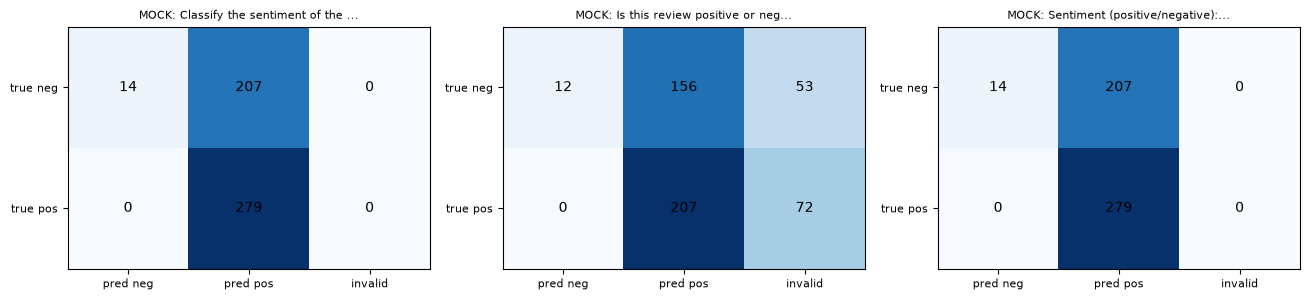

,pred_negative,pred_positive,invalid
true_negative,12,156,53
true_positive,0,207,72


In [6]:
fig, axes = plt.subplots(1, len(results_opt), figsize=(4.4 * len(results_opt), 3.4))
for ax, r in zip(np.atleast_1d(axes), results_opt):
    cm = np.array(r["metrics"]["confusion_matrix"])
    ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(3)); ax.set_xticklabels(["pred neg", "pred pos", "invalid"], fontsize=8)
    ax.set_yticks(range(2)); ax.set_yticklabels(["true neg", "true pos"], fontsize=8)
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, int(v), ha="center", va="center")
    ax.set_title("MOCK: " + r["prompt"][:30] + "...", fontsize=8)
plt.tight_layout(); plt.show()

r = results_opt[1]
pd.DataFrame(r["metrics"]["confusion_matrix"], index=["true_negative", "true_positive"],
             columns=["pred_negative", "pred_positive", "invalid"])

## 5. Prediction caching

Raw responses are cached per *(model id, prompt, text, inference config)*. A second evaluation of the same prompt
makes **no** predictor call. Changing the model id or any inference setting is a cache miss (never reuse answers
from a different model or temperature).

In [7]:
n_texts_sent = {"n": 0}
def counting_fn(prompt, texts):
    n_texts_sent["n"] += len(texts)
    return mock_predict_fn(prompt, texts)

again = evaluate_prompt(prompts[0], opt_s["text"], opt_s["label"], counting_fn, model_id=MODEL_ID,
                        inference_config=INFERENCE_CONFIG, cache=cache, split_name="opt")
print(f"same prompt again : {again['n_cached']}/{again['n_examples']} from cache, texts sent to predictor: {n_texts_sent['n']}")
assert n_texts_sent["n"] == 0

other = evaluate_prompt(prompts[0], opt_s["text"], opt_s["label"], counting_fn, model_id=MODEL_ID,
                        inference_config={**INFERENCE_CONFIG, "temperature": 0.7}, cache=cache, split_name="opt")
print(f"other temperature : {other['n_cached']}/{other['n_examples']} from cache, texts sent to predictor: {n_texts_sent['n']}")
assert n_texts_sent["n"] > 0

same prompt again : 500/500 from cache, texts sent to predictor: 0
other temperature : 0/500 from cache, texts sent to predictor: 500


## 6. Compare the prompts on the validation subset

The GA optimizes on `opt`; **`val` is where we compare promising prompts and choose the final one.**
The final test set stays untouched.

In [8]:
results_val = [
    evaluate_prompt(p, val_s["text"], val_s["label"], mock_predict_fn, model_id=MODEL_ID,
                    inference_config=INFERENCE_CONFIG, cache=cache, split_name="val", batch_size=100)
    for p in prompts
]
val_table = results_to_dataframe(results_val)[cols].round(4)
print("MOCK RESULTS (not an LLM)")
display(val_table)

best = int(val_table["f1_macro"].idxmax())
print("Prompt selected on VALIDATION macro F1 (mock):", prompts[best])

MOCK RESULTS (not an LLM)


,prompt,accuracy,precision_macro,recall_macro,f1_macro,n_invalid,invalid_rate
0,Classify the sentiment of the text as positive...,0.580,0.7470,0.5254,0.4142,0,0.00
1,Is this review positive or negative? Explain b...,0.436,0.7363,0.3949,0.3635,125,0.25
2,Sentiment (positive/negative):,0.580,0.7470,0.5254,0.4142,0,0.00


Prompt selected on VALIDATION macro F1 (mock): Classify the sentiment of the text as positive or negative. Answer with one word.


The **final test** would only be loaded now, after the choice is frozen, to compare the manual baseline and the
selected GA prompt **with the same model id and the same inference config**. It is *not executed* in this demo:

```python
from sst2_data import load_final_test
test = load_final_test(confirm=True)      # once, at the very end
# evaluate_prompt(baseline_prompt, test["text"], test["label"], real_predict_fn, model_id=..., inference_config=...)
# evaluate_prompt(best_ga_prompt,  test["text"], test["label"], real_predict_fn, model_id=..., inference_config=...)
```

## 7. Save results

* JSON: complete information (prompt, model, config, metrics, confusion matrix, per-example responses).
* CSV: one summary row per evaluation (good for logging every candidate of every GA generation).

In [9]:
all_results = results_opt + results_val
save_results(all_results, ROOT / "results" / "demo_results.json")
save_results(all_results, ROOT / "results" / "demo_results.csv", append=False)   # append=True (default) adds rows to an existing CSV
pd.read_csv(ROOT / "results" / "demo_results.csv")[["split", "model_id", "prompt", "f1_macro", "accuracy", "n_invalid"]].round(4)

,split,model_id,prompt,f1_macro,accuracy,n_invalid
0,opt,MOCK-keyword-lexicon-v1,Classify the sentiment of the text as positive...,0.4243,0.586,0
1,opt,MOCK-keyword-lexicon-v1,Is this review positive or negative? Explain b...,0.3739,0.438,125
2,opt,MOCK-keyword-lexicon-v1,Sentiment (positive/negative):,0.4243,0.586,0
3,val,MOCK-keyword-lexicon-v1,Classify the sentiment of the text as positive...,0.4142,0.580,0
4,val,MOCK-keyword-lexicon-v1,Is this review positive or negative? Explain b...,0.3635,0.436,125
5,val,MOCK-keyword-lexicon-v1,Sentiment (positive/negative):,0.4142,0.580,0


## 8. Replacing the mock with a real LLM

Only `predict_fn` changes. The LLM developer writes an adapter with the same contract, for example:

```python
def real_predict_fn(prompt, texts):
    responses = []
    for text in texts:
        try:
            # call the agreed free model here (e.g. an open-source model on Kaggle) with the SAME settings every time
            answer = my_model.generate(f"{prompt}\n\nText: {text}\nAnswer:", temperature=0.0, max_new_tokens=5)
        except Exception:
            answer = None            # failed call -> counted as invalid and NOT cached, so it is retried later
        responses.append(answer)
    return responses                 # list of raw strings, one per text, same order

result = evaluate_prompt(candidate_prompt, opt_s["text"], opt_s["label"], real_predict_fn,
                         model_id="<model name + version>", inference_config={"temperature": 0.0, "max_new_tokens": 5},
                         cache=cache, split_name="opt")
fitness = result["metrics"]["f1_macro"]
```

Rules: same model id and inference config for the manual baseline and every evolved prompt; use a **new cache file**
(e.g. `cache/<model>.jsonl`) for real runs and never mix it with the mock demo cache.